# Thyroid Cancer Recurrence: AdaBoost Classification
**Author:** Justin Williams  
**Date:** 11/23/2026

A demonstration of the AdaBoost classification model. The notebook compares two evaluation methods: train/test splits and 5-fold cross-validation.

## Contents

1. Background
2. Setup and Constants
3. Load Data
4. Preprocessing
5. Model Pipeline
6. Evaluation
7. Results


## 1. Background

A `AdaBoostClassifier` is a meta-estimator that fits copies of a base classifier on a dataset, making adjustments across each copy. The model focuses on more difficult cases with each iteration. This model uses a decision tree classifier as a base.


## 2. Setup and Constants

In [1]:
import numpy as np
import pandas as pd
import shap
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn import preprocessing
from sklearn.metrics import (
    classification_report, 
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split
)

In [2]:
TARGET_COL = "Recurred"
CATEGORICAL_COLS = [
    "Gender",
    "Smoking",
    "Hx Smoking",
    "Hx Radiotherapy",
    "Thyroid Function",
    "Physical Examination",
    "Adenopathy",
    "Pathology",
    "Focality",
    "Risk",
    "T",
    "N",
    "M",
    "Stage",
    "Response"
]

RAND_STATE = 42

TEST_SIZES = [0.2, 0.25, 0.3]

PARAM_DICT = {
    "clf__learning_rate": [0.75, 1.0, 1.25],
    "clf__n_estimators": [50, 75, 100],
    "clf__estimator__max_features": [None, "sqrt", "log2"],
    "clf__estimator__max_depth": [5, 10, 15],
    "pca__n_components": [18, 19, 20, 21, 22]
}

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", '{:.3f}'.format)
shap.initjs()

In [ ]:
# Format a confusion matrix (cm) into a Pandas dataframe
def make_cm_frame(cm):
    return pd.DataFrame(
        cm,
        index=["Actual No", "Actual Yes"],
        columns=["Pred No", "Pred Yes"]
    )

# Format a grid search result table to show the top score across each pca parameter
def make_pca_frame(cv_res):
    cv_df = pd.DataFrame(cv_res).sort_values("rank_test_score")
    out = cv_df.groupby("param_pca__n_components", dropna=False).head(1).sort_values("param_pca__n_components")
    return out[["param_pca__n_components", "rank_test_score", "mean_test_score", "std_test_score"]]

### Cross-Validation Setup

`StratifiedKFold` keeps the ratio of target values consistent across each fold.

In [4]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RAND_STATE)

### SMOTE Setup

Only 28.2% of patients recurred. SMOTE ensures that the target data is not imbalanced during training.

In [5]:
smote = SMOTE(sampling_strategy="minority", random_state=RAND_STATE)

## 3. Load Data

In [6]:
df = pd.read_csv("../data/processed/Thyroid_Diff.csv")

print(df.shape)

df.head()

(383, 17)


,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiotherapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  T                     383 non-null    str  
 12  N                     383 non-null    str  
 13  M                     383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

## 4. Preprocessing

`X` holds the features to train on. `y` holds the target to predict. The target column maps Yes/No to 1/0.

In [8]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL].map({"No": 0, "Yes": 1})

print(y.value_counts())
print(f"\nRecurrence rate: {y.mean():.1%}")

Recurred
0    275
1    108
Name: count, dtype: int64

Recurrence rate: 28.2%


### Encoding and Scaling

Columns listed in `CATEGORICAL_COLS` are transformed using One-Hot Encoding. The `Age` column is scaled to have a mean of 0 and a standard deviation of 1. The `ColumnTransformer` is used to avoid data leakage from encoding training and testing data together. It produces the same columns, even if future data is missing any categories.


In [9]:
colTransform = ColumnTransformer(
    transformers=[
        ("cat", preprocessing.OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
        ("num", preprocessing.StandardScaler(), ["Age"])
    ],
    verbose_feature_names_out=False
)

## 5. Pipeline Setup

In [10]:
model = Pipeline([
    ("trans", colTransform),
    ("smote", smote),
    ("pca", PCA(random_state=RAND_STATE)),
    ("clf", AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RAND_STATE), random_state=RAND_STATE))
])

model

,steps,"[('trans', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weight

### Hyperparameter Tuning - GridSearchCV

Adjust the parameters of the Random Forest classifier in the pipeline to find the combination of parameters with the best results. Fit to each train/test split.

In [11]:
gs = GridSearchCV(model, PARAM_DICT)

## 6. Evaluation

### Train-Test Splits

In [ ]:
results = []

for size in TEST_SIZES:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=size, stratify=y, random_state=RAND_STATE
    )

    gs = GridSearchCV(model, PARAM_DICT)
    gs.fit(X_train, y_train)
    y_pred = gs.predict(X_test)

    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    roc_auc = auc(fpr, tpr)

    enc = gs.best_estimator_.named_steps["trans"]
    pca = gs.best_estimator_.named_steps["pca"]
    loadings = pd.DataFrame(
        (pca.components_.T * np.sqrt(pca.explained_variance_)),
        index=enc.get_feature_names_out(),
        columns=(f"PC{i+1}" for i in range(pca.n_components_))
    )

    def predict_fn(arr):
        temp_df = pd.DataFrame(arr, columns=X_test.columns)
        temp_df = temp_df.astype(X_test.dtypes.to_dict())
        return gs.predict(temp_df)

    explainer = shap.KernelExplainer(predict_fn, X_test)
    shap_vals = explainer.shap_values(X_test)

    results.append({
        "Method": f"Train/Test split ({size})",
        "Report": classification_report(y_test, y_pred, target_names=["No", "Yes"], output_dict=True),
        "CM": confusion_matrix(y_test, y_pred),
        "ROCAUC": roc_auc,
        "Best": gs.best_params_,
        "SHAP": shap.Explanation(shap_vals, y_test, X_test, X),
        "PCAExVar": pca.explained_variance_ratio_,
        "FeatLoad": loadings,
        "PCARank": make_pca_frame(gs.cv_results_),
    })

  0%|          | 0/77 [00:00<?, ?it/s]

  0%|          | 0/96 [00:00<?, ?it/s]

Using 115 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/115 [00:00<?, ?it/s]

### 5-Fold Cross-Validation

In [13]:
folds = []

for i_train, i_test in kfold.split(X, y):
    X_train, X_test, y_train, y_test = X.iloc[i_train], X.iloc[i_test], y.iloc[i_train], y.iloc[i_test]
    gs.fit(X_train, y_train)

    enc = gs.best_estimator_.named_steps["trans"]
    pca = gs.best_estimator_.named_steps["pca"]
    loadings = pd.DataFrame(
        (pca.components_.T * np.sqrt(pca.explained_variance_)),
        index=enc.get_feature_names_out(),
        columns=(f"PC{i+1}" for i in range(pca.n_components_))
    )

    def predict_fn(arr):
        temp_df = pd.DataFrame(arr, columns=X_test.columns)
        temp_df = temp_df.astype(X_test.dtypes.to_dict())
        return gs.predict(temp_df)

    explainer = shap.KernelExplainer(predict_fn, X_test)
    shap_vals = explainer.shap_values(X_test)

    folds.append({
        "i_train": i_train,
        "i_test": i_test,
        "acc": gs.score(X_test, y_test),
        "pred": gs.predict(X_test),
        "test": y_test,
        "params": gs.best_params_,
        "loadings": loadings,
        "cv_res": gs.cv_results_,
        "shap": shap.Explanation(shap_vals, y_test, X_test, X),
        "variance": pca.explained_variance_ratio_
    })

fold_scores = [f.get("acc") for f in folds]

high = max(fold_scores)
high_fold = folds[fold_scores.index(high)]
low = min(fold_scores)
low_fold = folds[fold_scores.index(low)]
avg = np.mean(fold_scores)

cv_cm = confusion_matrix(high_fold["test"], high_fold["pred"])

fpr, tpr, thresholds = roc_curve(high_fold["test"], high_fold["pred"])
roc_auc = auc(fpr, tpr)
    
results.append({
    "Method": "5-fold cross-validation (max)",
    "Report": classification_report(high_fold["test"], high_fold["pred"], target_names=["No", "Yes"], output_dict=True),
    "CM": cv_cm,
    "ROCAUC": roc_auc,
    "Best": high_fold["params"],
    "SHAP": high_fold["shap"],
    "PCAExVar": high_fold["variance"],
    "FeatLoad": high_fold["loadings"],
    "PCARank": make_pca_frame(high_fold["cv_res"])
})

cv_cm = confusion_matrix(low_fold["test"], low_fold["pred"])

fpr, tpr, thresholds = roc_curve(low_fold["test"], low_fold["pred"])
roc_auc = auc(fpr, tpr)

results.append({
    "Method": "5-fold cross-validation (min)",
    "Report": classification_report(low_fold["test"], low_fold["pred"], target_names=["No", "Yes"], output_dict=True),
    "CM": cv_cm,
    "ROCAUC": roc_auc,
    "Best": low_fold["params"],
    "SHAP": low_fold["shap"],
    "PCAExVar": low_fold["variance"],
    "PCARank": make_pca_frame(low_fold["cv_res"]),
    "FeatLoad": low_fold["loadings"]
})

# Compute average classification report and average ROC AUC statistics
cv_report_list = []
roc_auc_list = []
for f in folds:
    cv_report_list.append(pd.DataFrame(classification_report(f["test"], f["pred"], target_names=["No", "Yes"], output_dict=True)))
    fpr, tpr, thresholds = roc_curve(f["test"], f["pred"])
    roc_auc_list.append(auc(fpr, tpr))

cv_avg_report = pd.concat(cv_report_list).groupby(level=0).mean()
cv_avg_auc = np.mean(roc_auc_list)


  0%|          | 0/77 [00:00<?, ?it/s]

  0%|          | 0/77 [00:00<?, ?it/s]

  0%|          | 0/77 [00:00<?, ?it/s]

  0%|          | 0/76 [00:00<?, ?it/s]

  0%|          | 0/76 [00:00<?, ?it/s]

In [14]:
print(f"KFold Scores: {fold_scores}")
print(f"KFold Average: {avg}")

KFold Scores: [0.948051948051948, 0.935064935064935, 0.948051948051948, 0.9736842105263158, 0.8947368421052632]
KFold Average: 0.939917976760082


## 7. Results

### Classification Reports

In [15]:
for result in results:
    print(result["Method"])
    print(f"ROC AUC: {result["ROCAUC"]}")
    display(pd.DataFrame(result["Report"]))

print("5-fold cross-validation (avg)")
print(cv_avg_auc)
display(cv_avg_report)


Train/test split (0.2)
ROC AUC: 0.9454545454545454


,No,Yes,accuracy,macro avg,weighted avg
precision,0.964,0.952,0.961,0.958,0.961
recall,0.982,0.909,0.961,0.945,0.961
f1-score,0.973,0.930,0.961,0.952,0.961
support,55.000,22.000,0.961,77.000,77.000


Train/test split (0.25)
ROC AUC: 0.9444444444444444


,No,Yes,accuracy,macro avg,weighted avg
precision,0.958,1.000,0.969,0.979,0.970
recall,1.000,0.889,0.969,0.944,0.969
f1-score,0.979,0.941,0.969,0.960,0.968
support,69.000,27.000,0.969,96.000,96.000


Train/test split (0.3)
ROC AUC: 0.9375


,No,Yes,accuracy,macro avg,weighted avg
precision,0.954,1.000,0.965,0.977,0.967
recall,1.000,0.875,0.965,0.938,0.965
f1-score,0.976,0.933,0.965,0.955,0.964
support,83.000,32.000,0.965,115.000,115.000


... (2 outputs left out)

5-fold cross-validation (min)
ROC AUC: 0.8536796536796537


,No,Yes,accuracy,macro avg,weighted avg
precision,0.912,0.842,0.895,0.877,0.893
recall,0.945,0.762,0.895,0.854,0.895
f1-score,0.929,0.800,0.895,0.864,0.893
support,55.000,21.000,0.895,76.000,76.000


5-fold cross-validation (avg)
0.9216450216450216


,No,Yes,accuracy,macro avg,weighted avg
f1-score,0.959,0.891,0.940,0.925,0.939
precision,0.954,0.907,0.940,0.930,0.941
recall,0.964,0.880,0.940,0.922,0.940
support,55.000,21.600,0.940,76.600,76.600


### Confusion Matrices

The rows represent the actual classes, and the columns represent predicted classes. All correct predictions lie on the diagonal:

| | Pred No | Pred Yes |
|---|---|---|
| **Actual No** | True negatives (TN) | False positives (FP) |
| **Actual Yes** | False negatives (FN) | True positives (TP) |

Train/Test Split matrices count the test set while the Cross-Validation matrix counts the entire dataset.

In [16]:
for result in results:
    print(result["Method"])
    display(make_cm_frame(result["CM"]))


Train/test split (0.2)


,Pred No,Pred Yes
Actual No,54,1
Actual Yes,2,20


Train/test split (0.25)


,Pred No,Pred Yes
Actual No,69,0
Actual Yes,3,24


Train/test split (0.3)


,Pred No,Pred Yes
Actual No,83,0
Actual Yes,4,28


5-fold cross-validation (max)


,Pred No,Pred Yes
Actual No,53,2
Actual Yes,0,21


5-fold cross-validation (min)


,Pred No,Pred Yes
Actual No,52,3
Actual Yes,5,16


### Hyperparameter Tuning Resuls

The following hyper parameters for the Random Forest model were tuned:
1. `max_depth` - How deep each tree can go
2. `max_features` - Total number of features each tree can train on
3. `n_estimators` - Number of trees voting


In [17]:
for result in results:
    print(result["Method"])
    print(result["Best"])
    print()

Train/test split (0.2)
{'clf__estimator__max_depth': 5, 'clf__estimator__max_features': None, 'clf__learning_rate': 1.25, 'clf__n_estimators': 75, 'pca__n_components': 21}

Train/test split (0.25)
{'clf__estimator__max_depth': 5, 'clf__estimator__max_features': 'sqrt', 'clf__learning_rate': 1.0, 'clf__n_estimators': 75, 'pca__n_components': 20}

Train/test split (0.3)
{'clf__estimator__max_depth': 5, 'clf__estimator__max_features': 'sqrt', 'clf__learning_rate': 0.75, 'clf__n_estimators': 50, 'pca__n_components': 19}

5-fold cross-validation (max)
{'clf__estimator__max_depth': 5, 'clf__estimator__max_features': None, 'clf__learning_rate': 1.0, 'clf__n_estimators': 75, 'pca__n_components': 19}

5-fold cross-validation (min)
{'clf__estimator__max_depth': 5, 'clf__estimator__max_features': None, 'clf__learning_rate': 1.25, 'clf__n_estimators': 50, 'pca__n_components': 21}



### SHAP Values

SHAP explains how much each feature helps or hurts predictions.

Train/test split (0.2)


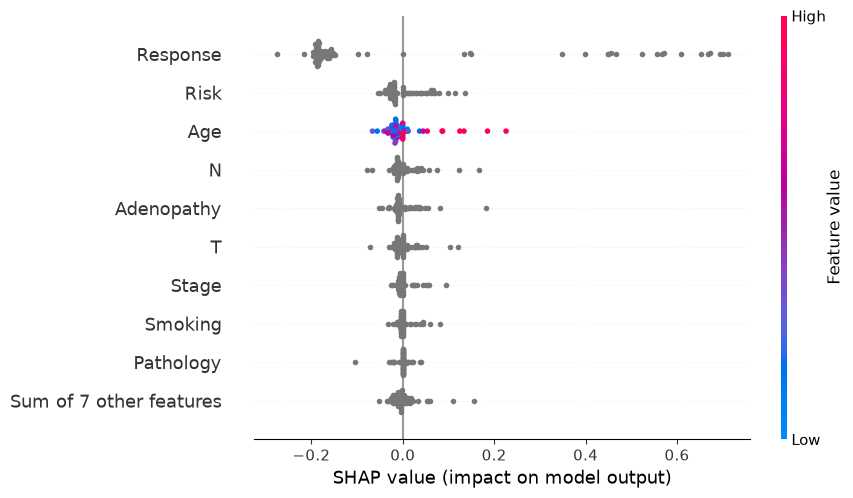

Train/test split (0.25)


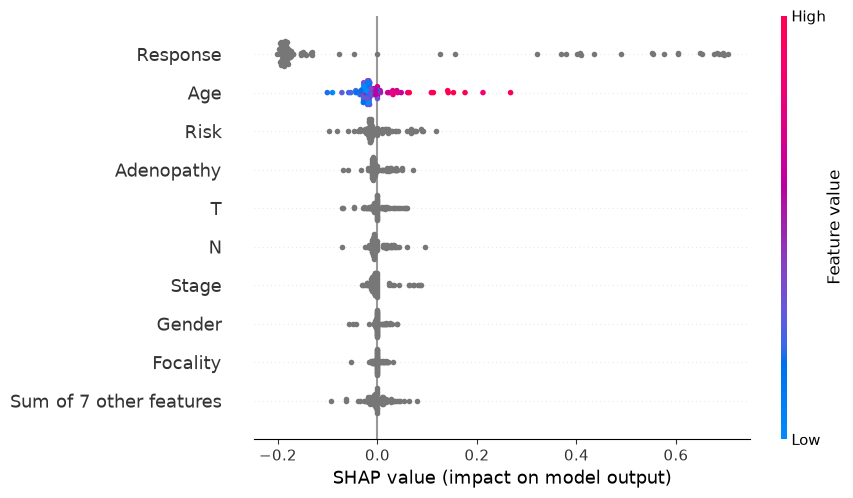

Train/test split (0.3)


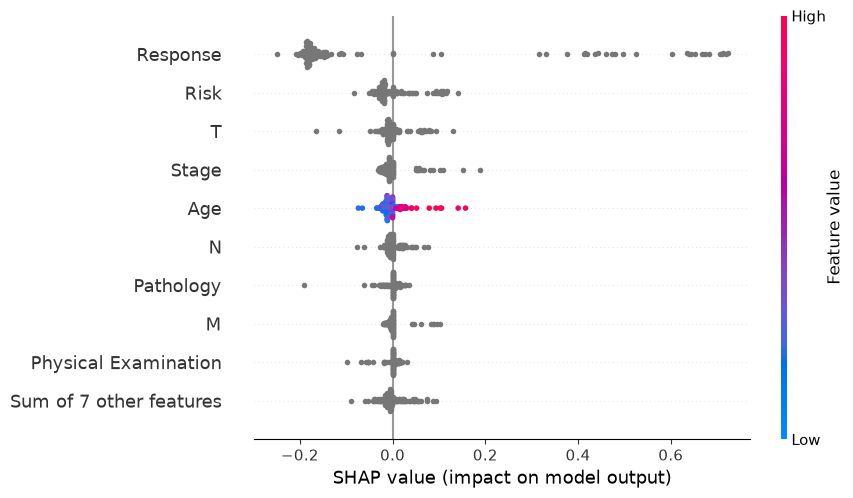

5-fold cross-validation (max)


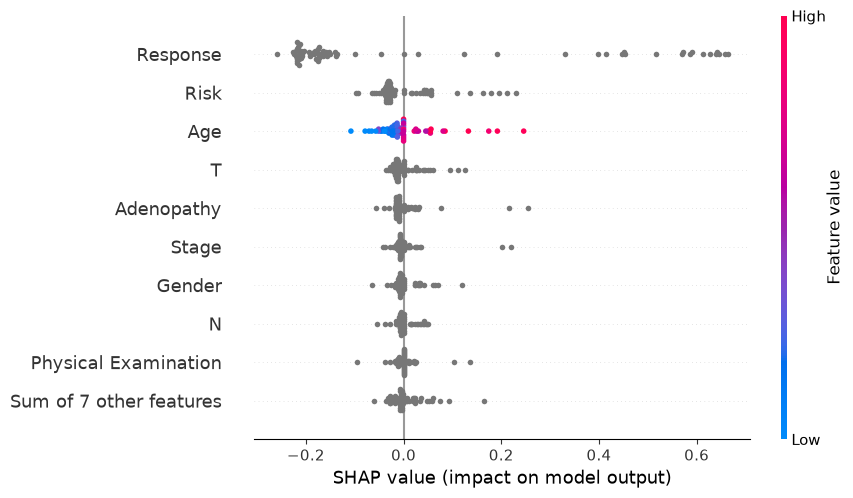

5-fold cross-validation (min)


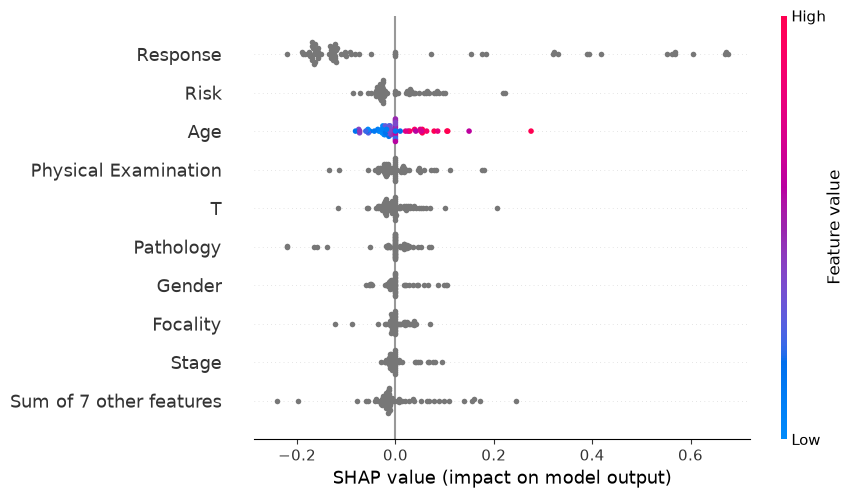

In [18]:
for result in results:
    print(result["Method"])
    shap.plots.beeswarm(result["SHAP"])

### PCA Results

#### Explained Variance Ratio

The explained variance ratio is the ratio of a principal component's eigenvalue to the sum of the eigenvalues of all principal components. It can be used to assess how much variance is captured by each principal component.

Train/test split (0.2)
PC1: 0.282
PC2: 0.156
PC3: 0.064
PC4: 0.060
PC5: 0.048
PC6: 0.044
PC7: 0.040
PC8: 0.037
PC9: 0.029
PC10: 0.023
PC11: 0.023
PC12: 0.021
PC13: 0.018
PC14: 0.018
PC15: 0.015
PC16: 0.014
PC17: 0.012
PC18: 0.011
PC19: 0.011
PC20: 0.008
PC21: 0.007

Train/test split (0.25)
PC1: 0.279
PC2: 0.161
PC3: 0.064
PC4: 0.063
PC5: 0.048
PC6: 0.040
PC7: 0.038
PC8: 0.035
PC9: 0.028
PC10: 0.026
PC11: 0.022
PC12: 0.020
PC13: 0.019
PC14: 0.018
PC15: 0.017
PC16: 0.014
PC17: 0.013
PC18: 0.012
PC19: 0.011
PC20: 0.009

Train/test split (0.3)
PC1: 0.274
PC2: 0.159
PC3: 0.066
PC4: 0.056
PC5: 0.047
PC6: 0.043
PC7: 0.037
PC8: 0.036
PC9: 0.030
PC10: 0.027
PC11: 0.022
PC12: 0.022
PC13: 0.020
PC14: 0.017
PC15: 0.016
PC16: 0.015
PC17: 0.012
PC18: 0.012
PC19: 0.011

5-fold cross-validation (max)
PC1: 0.269
PC2: 0.165
PC3: 0.065
PC4: 0.063
PC5: 0.048
PC6: 0.044
PC7: 0.039
PC8: 0.036
PC9: 0.028
PC10: 0.025
PC11: 0.021
PC12: 0.020
PC13: 0.019
PC14: 0.017
PC15: 0.016
PC16: 0.014
PC17: 0.013
PC18: 0.0

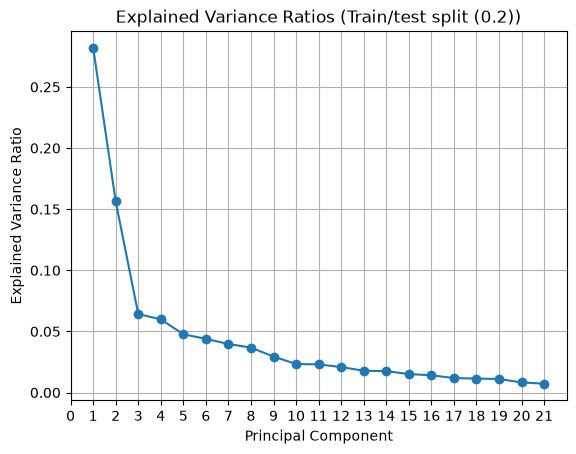

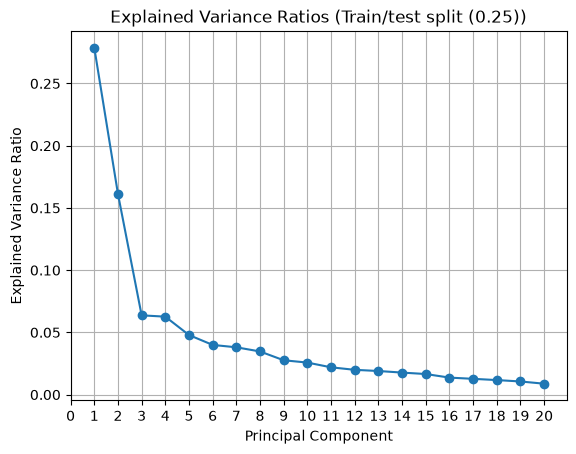

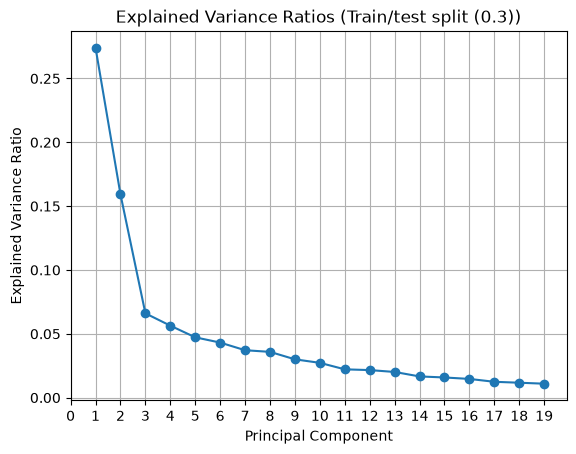

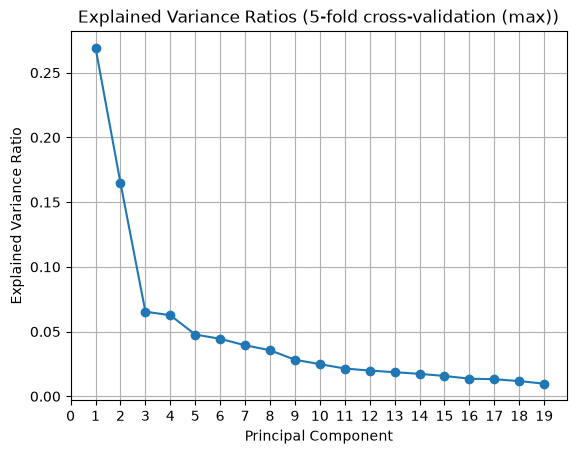

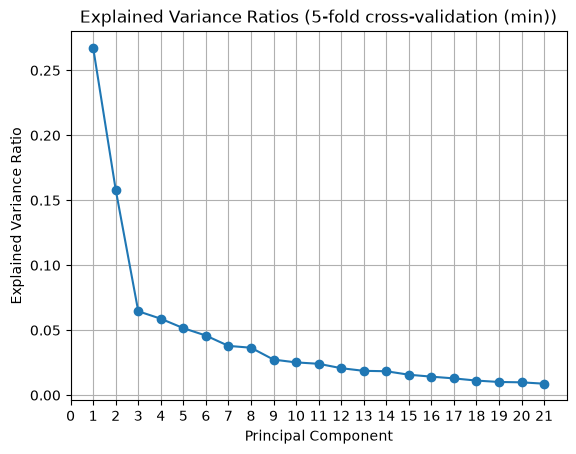

In [22]:
for result in results:
    print(result["Method"])

    for i, evr in enumerate(result["PCAExVar"]):
        print(f"PC{i+1}: {evr:.3f}")

    print()
    
    fig, ax = plt.subplots()

    x = np.arange(1, len(result["PCAExVar"]) + 1)
    y = result["PCAExVar"]

    

    ax.plot(x, y, marker='o')
    ax.grid(True)
    ax.set_xlabel("Principal Component")
    ax.set_xticks(np.arange(0, (len(result["PCAExVar"]) + 1), 1))
    ax.set_ylabel("Explained Variance Ratio")
    ax.set_title(f"Explained Variance Ratios ({result["Method"]})")


#### Score Tables

Displays tables for each model showing their best score across 5 PCA component counts for each split.

In [20]:
for result in results:
    print(result["Method"])
    display(result["PCARank"])

Train/test split (0.2)


,param_pca__n_components,rank_test_score,mean_test_score,std_test_score
55,18,16,0.948,0.028
71,19,8,0.948,0.028
62,20,26,0.944,0.022
38,21,1,0.954,0.024
119,22,8,0.948,0.019


Train/test split (0.25)


,param_pca__n_components,rank_test_score,mean_test_score,std_test_score
105,18,20,0.934,0.021
11,19,15,0.937,0.036
67,20,1,0.944,0.028
78,21,7,0.941,0.033
99,22,24,0.934,0.030


Train/test split (0.3)


,param_pca__n_components,rank_test_score,mean_test_score,std_test_score
20,18,17,0.933,0.025
46,19,1,0.944,0.026
112,20,3,0.940,0.036
113,21,23,0.929,0.022
99,22,9,0.933,0.038


5-fold cross-validation (max)


,param_pca__n_components,rank_test_score,mean_test_score,std_test_score
20,18,10,0.866,0.071
21,19,1,0.883,0.075
102,20,15,0.856,0.137
63,21,4,0.879,0.088
9,22,14,0.857,0.121


5-fold cross-validation (min)


,param_pca__n_components,rank_test_score,mean_test_score,std_test_score
40,18,1,0.889,0.050
36,19,4,0.889,0.069
32,20,5,0.886,0.085
43,21,1,0.889,0.070
74,22,36,0.869,0.132


#### Feature Loadings

Matrix of feature loadings, explaining the impact of each feature across each component for each split.


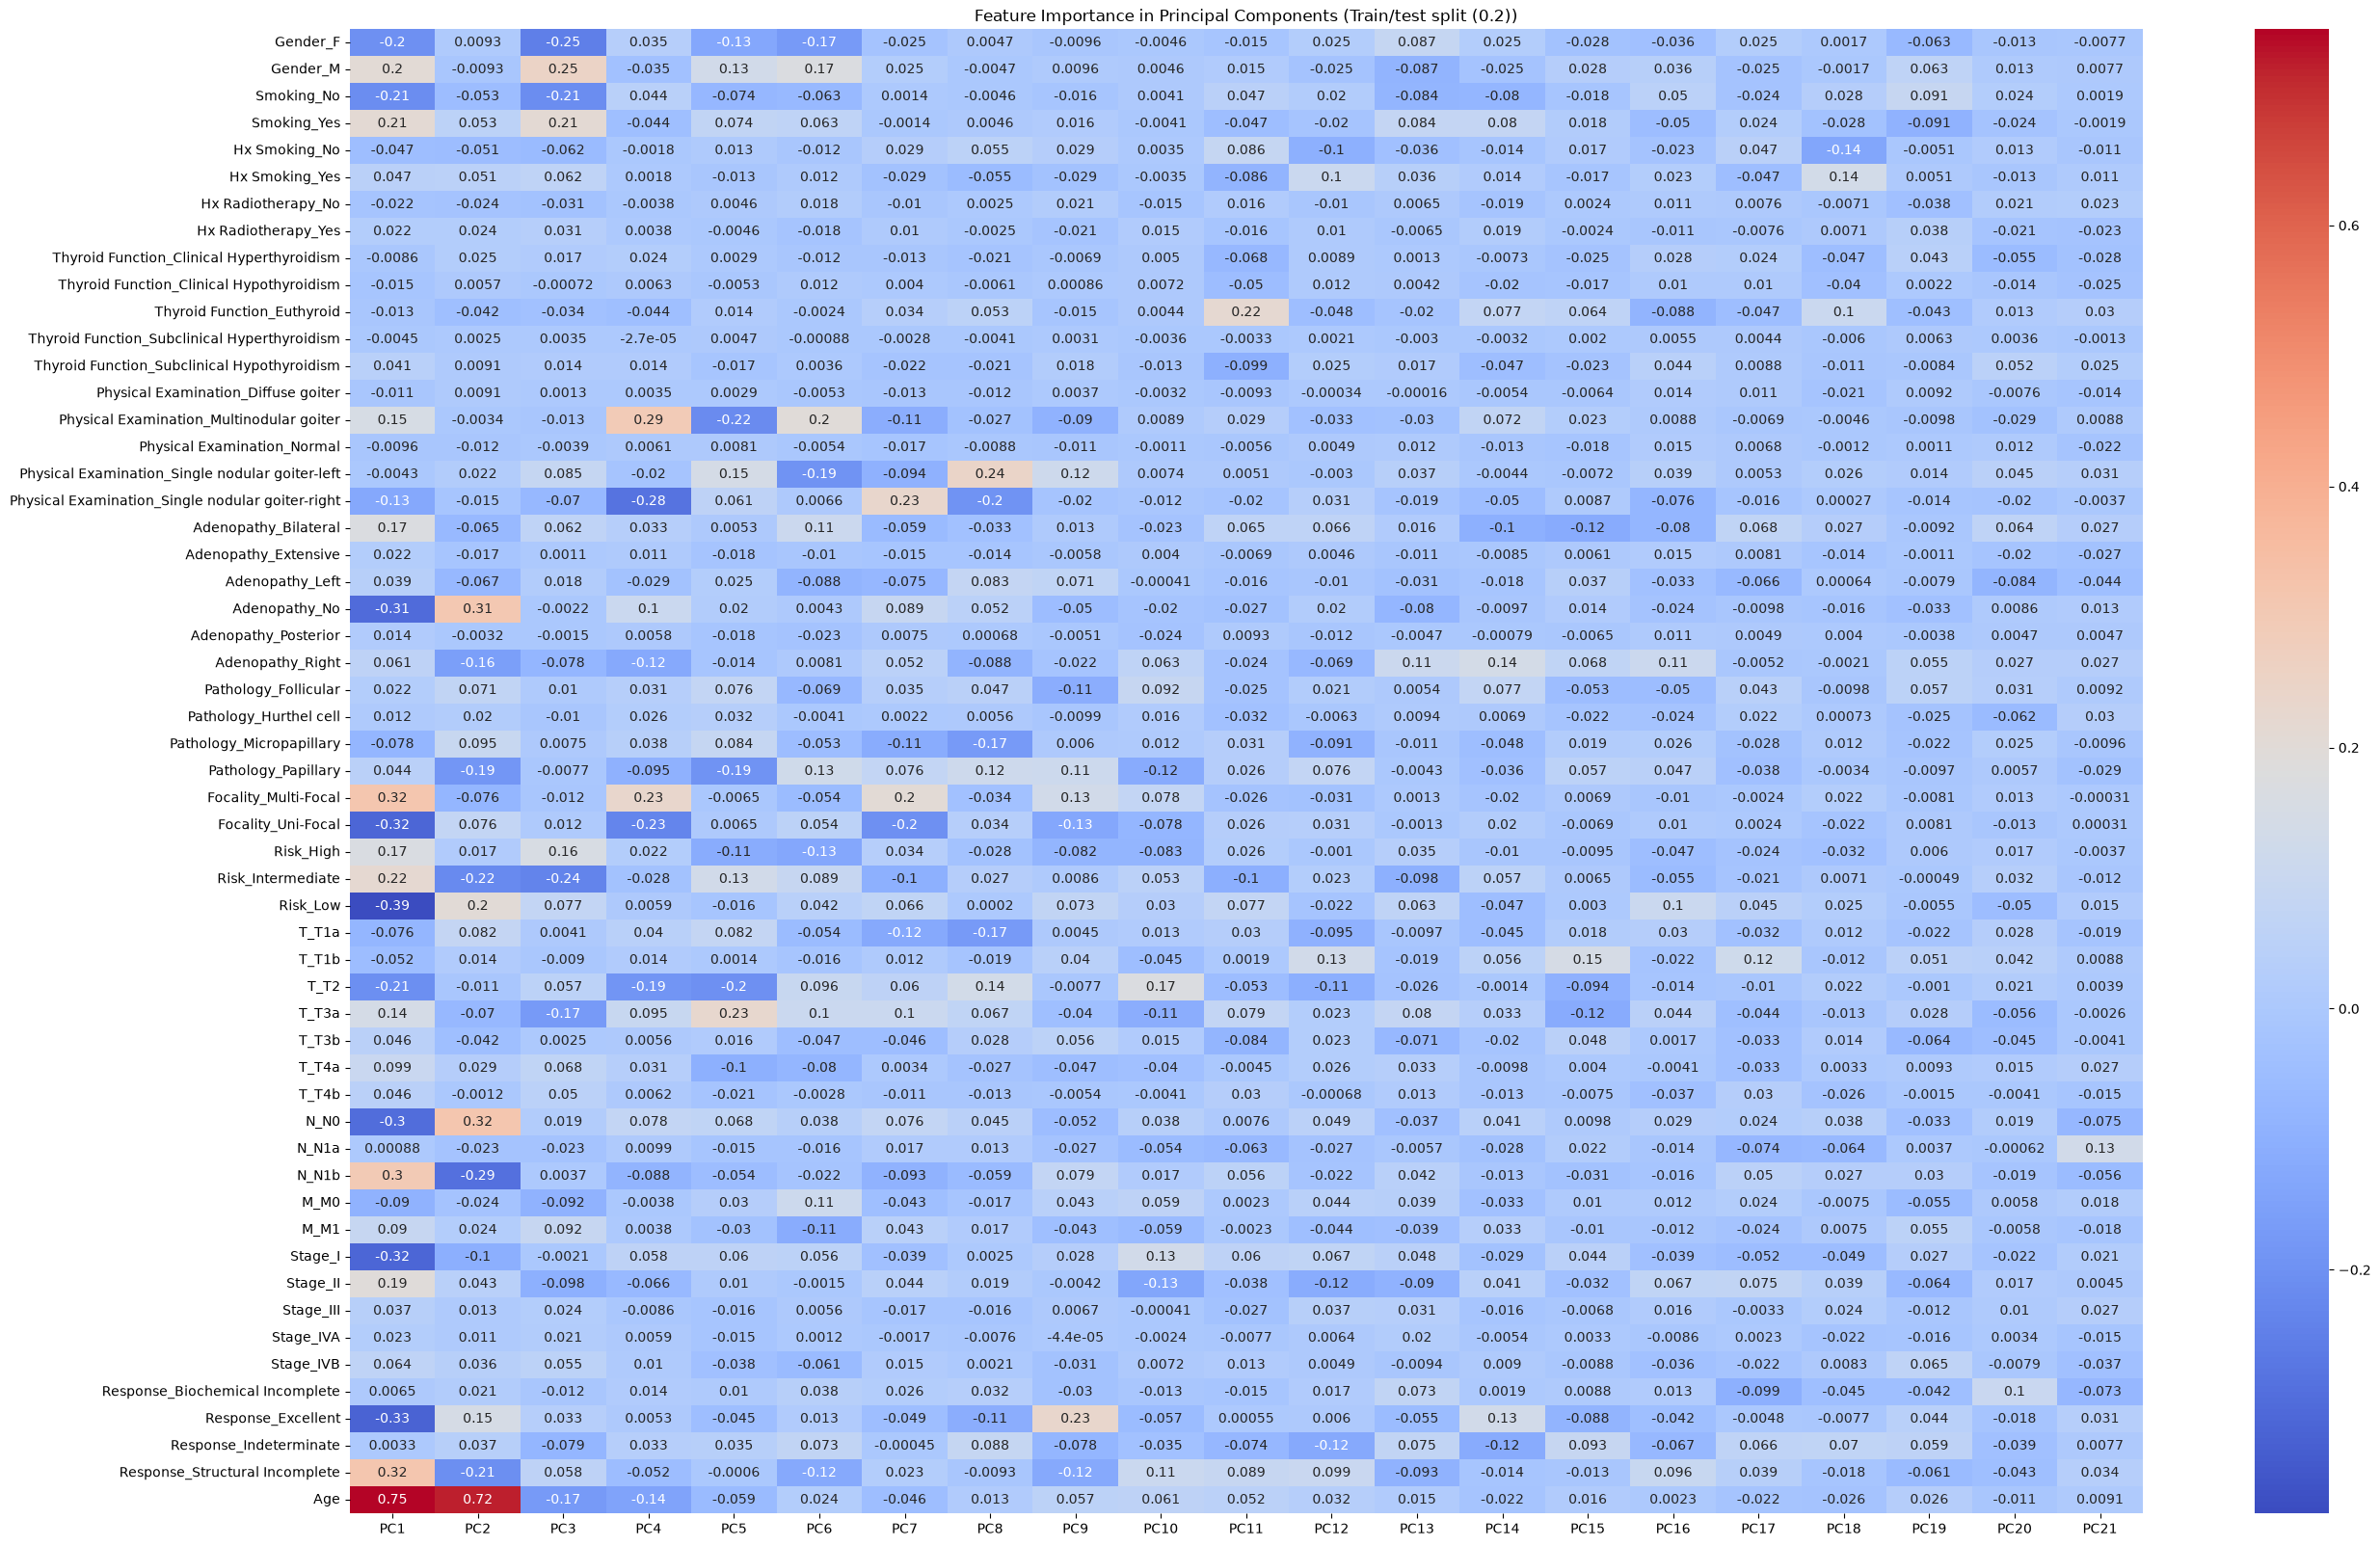

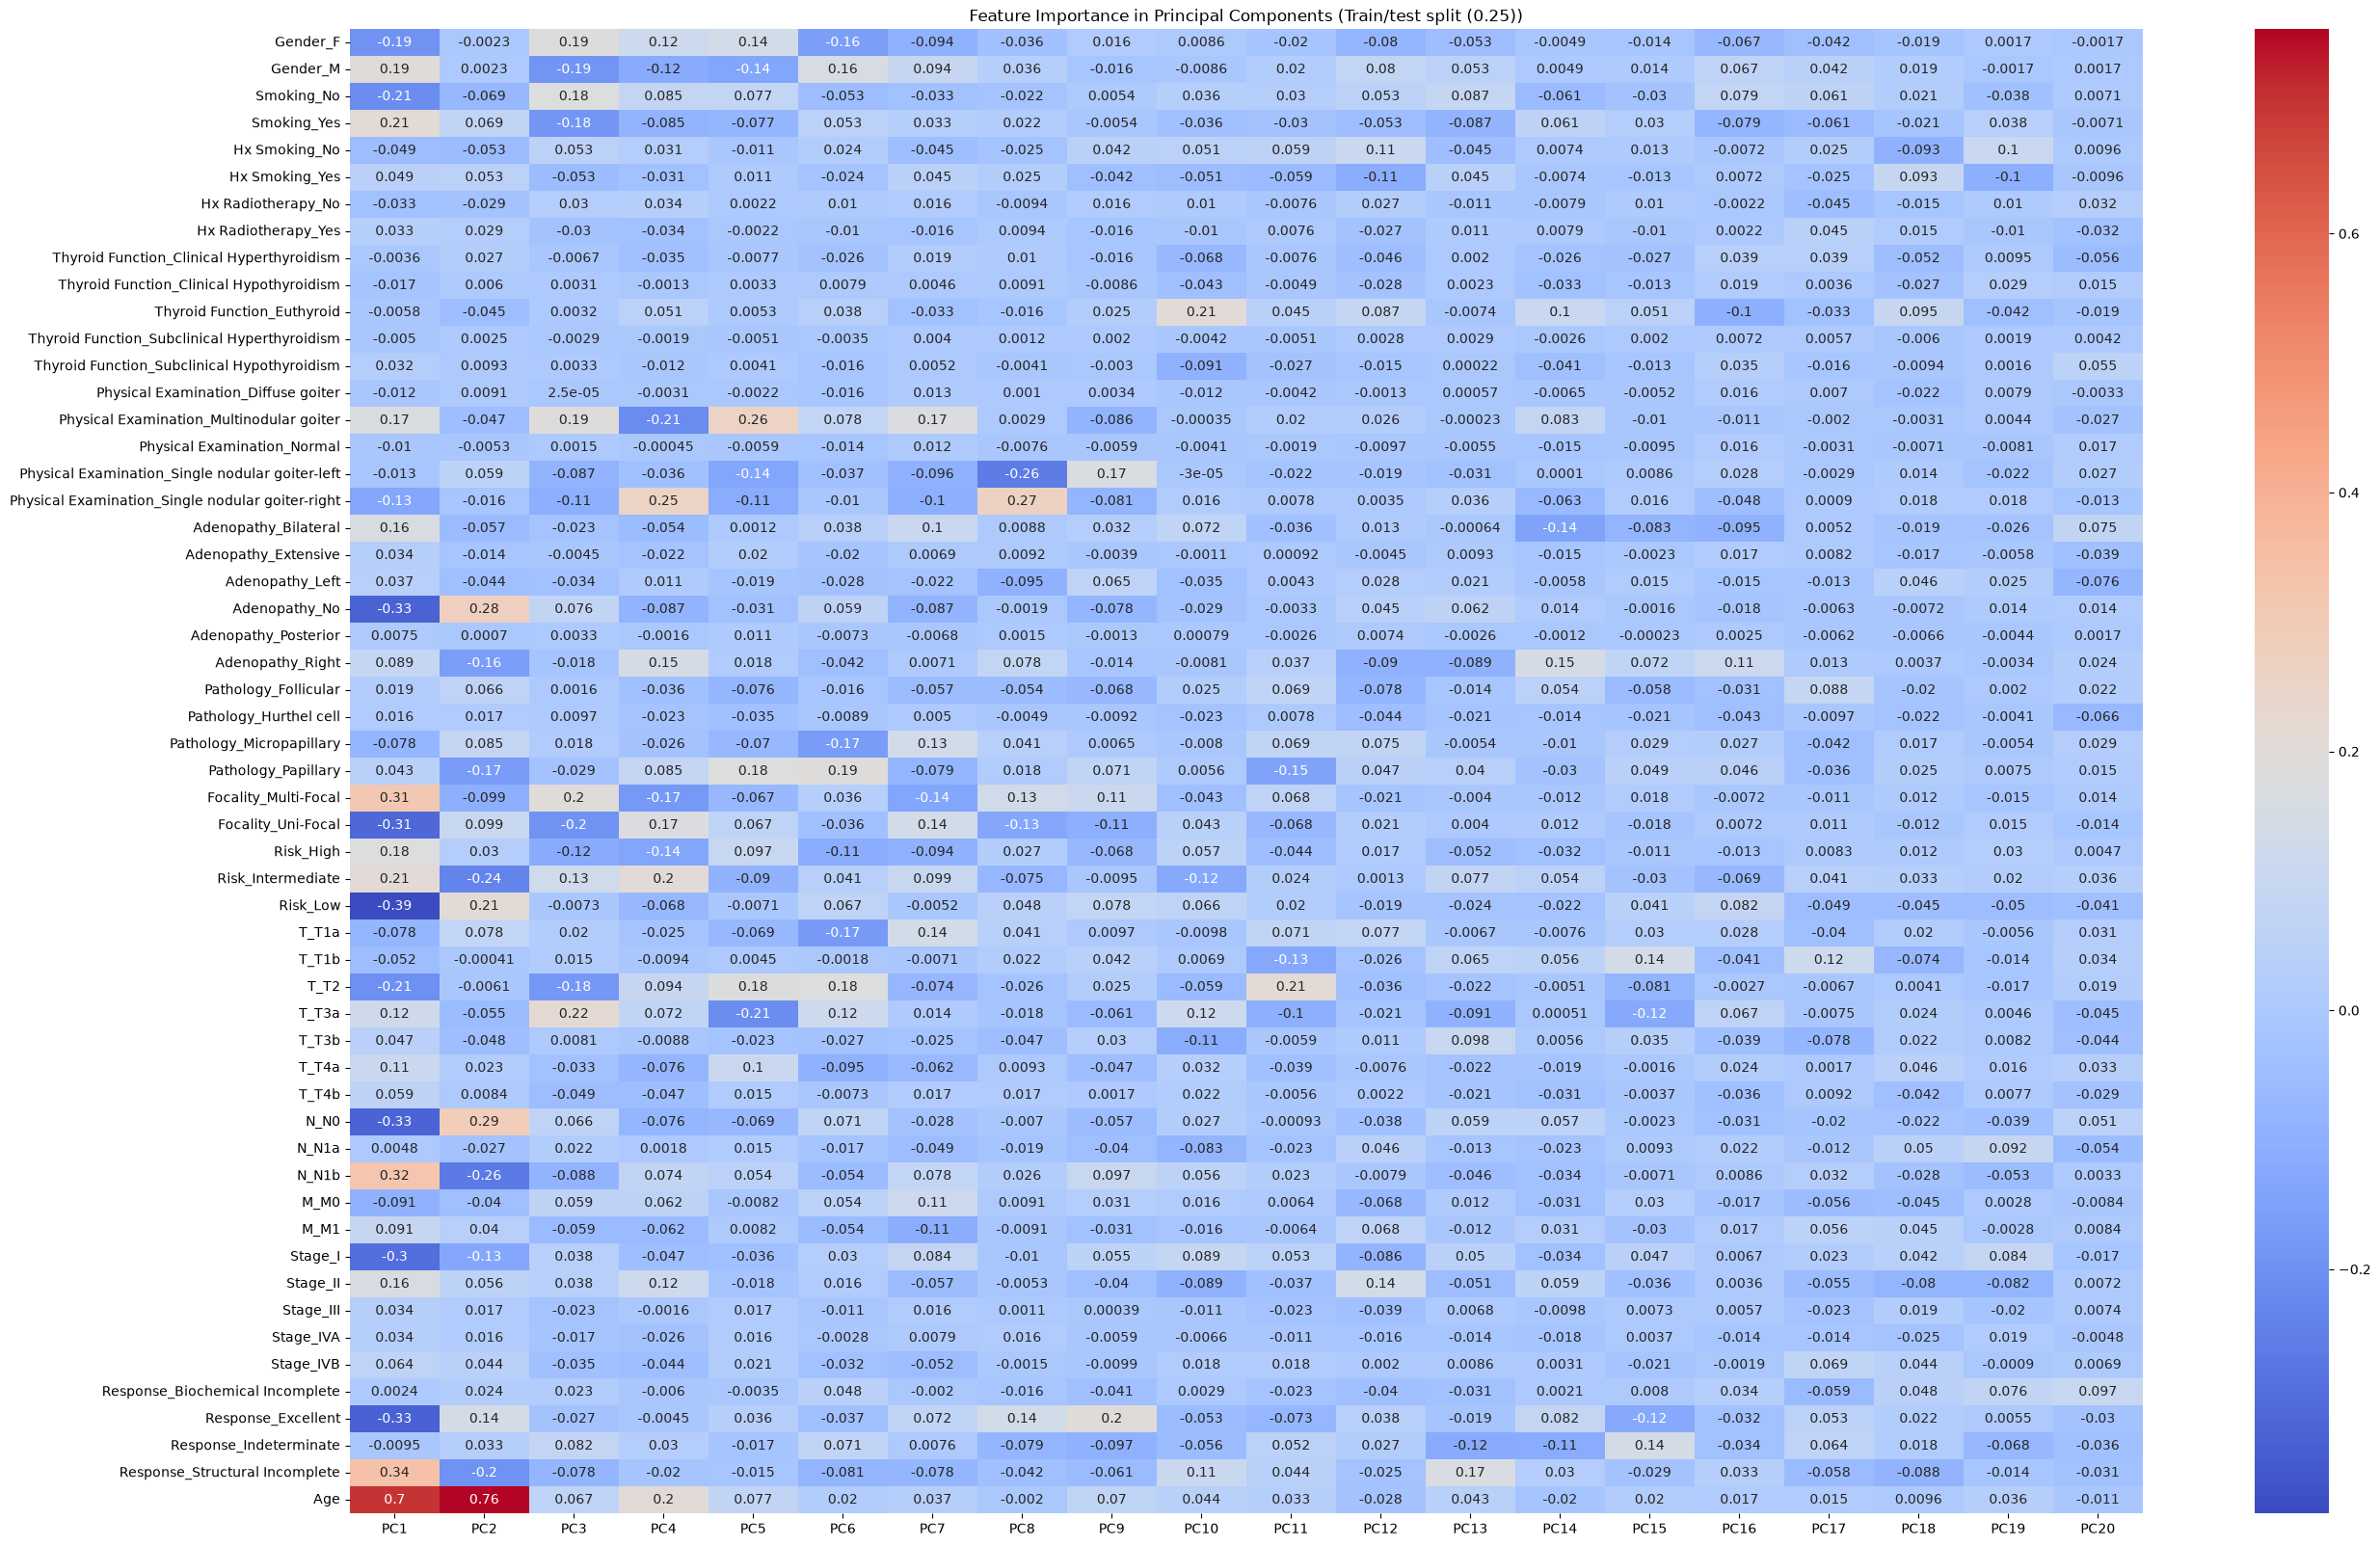

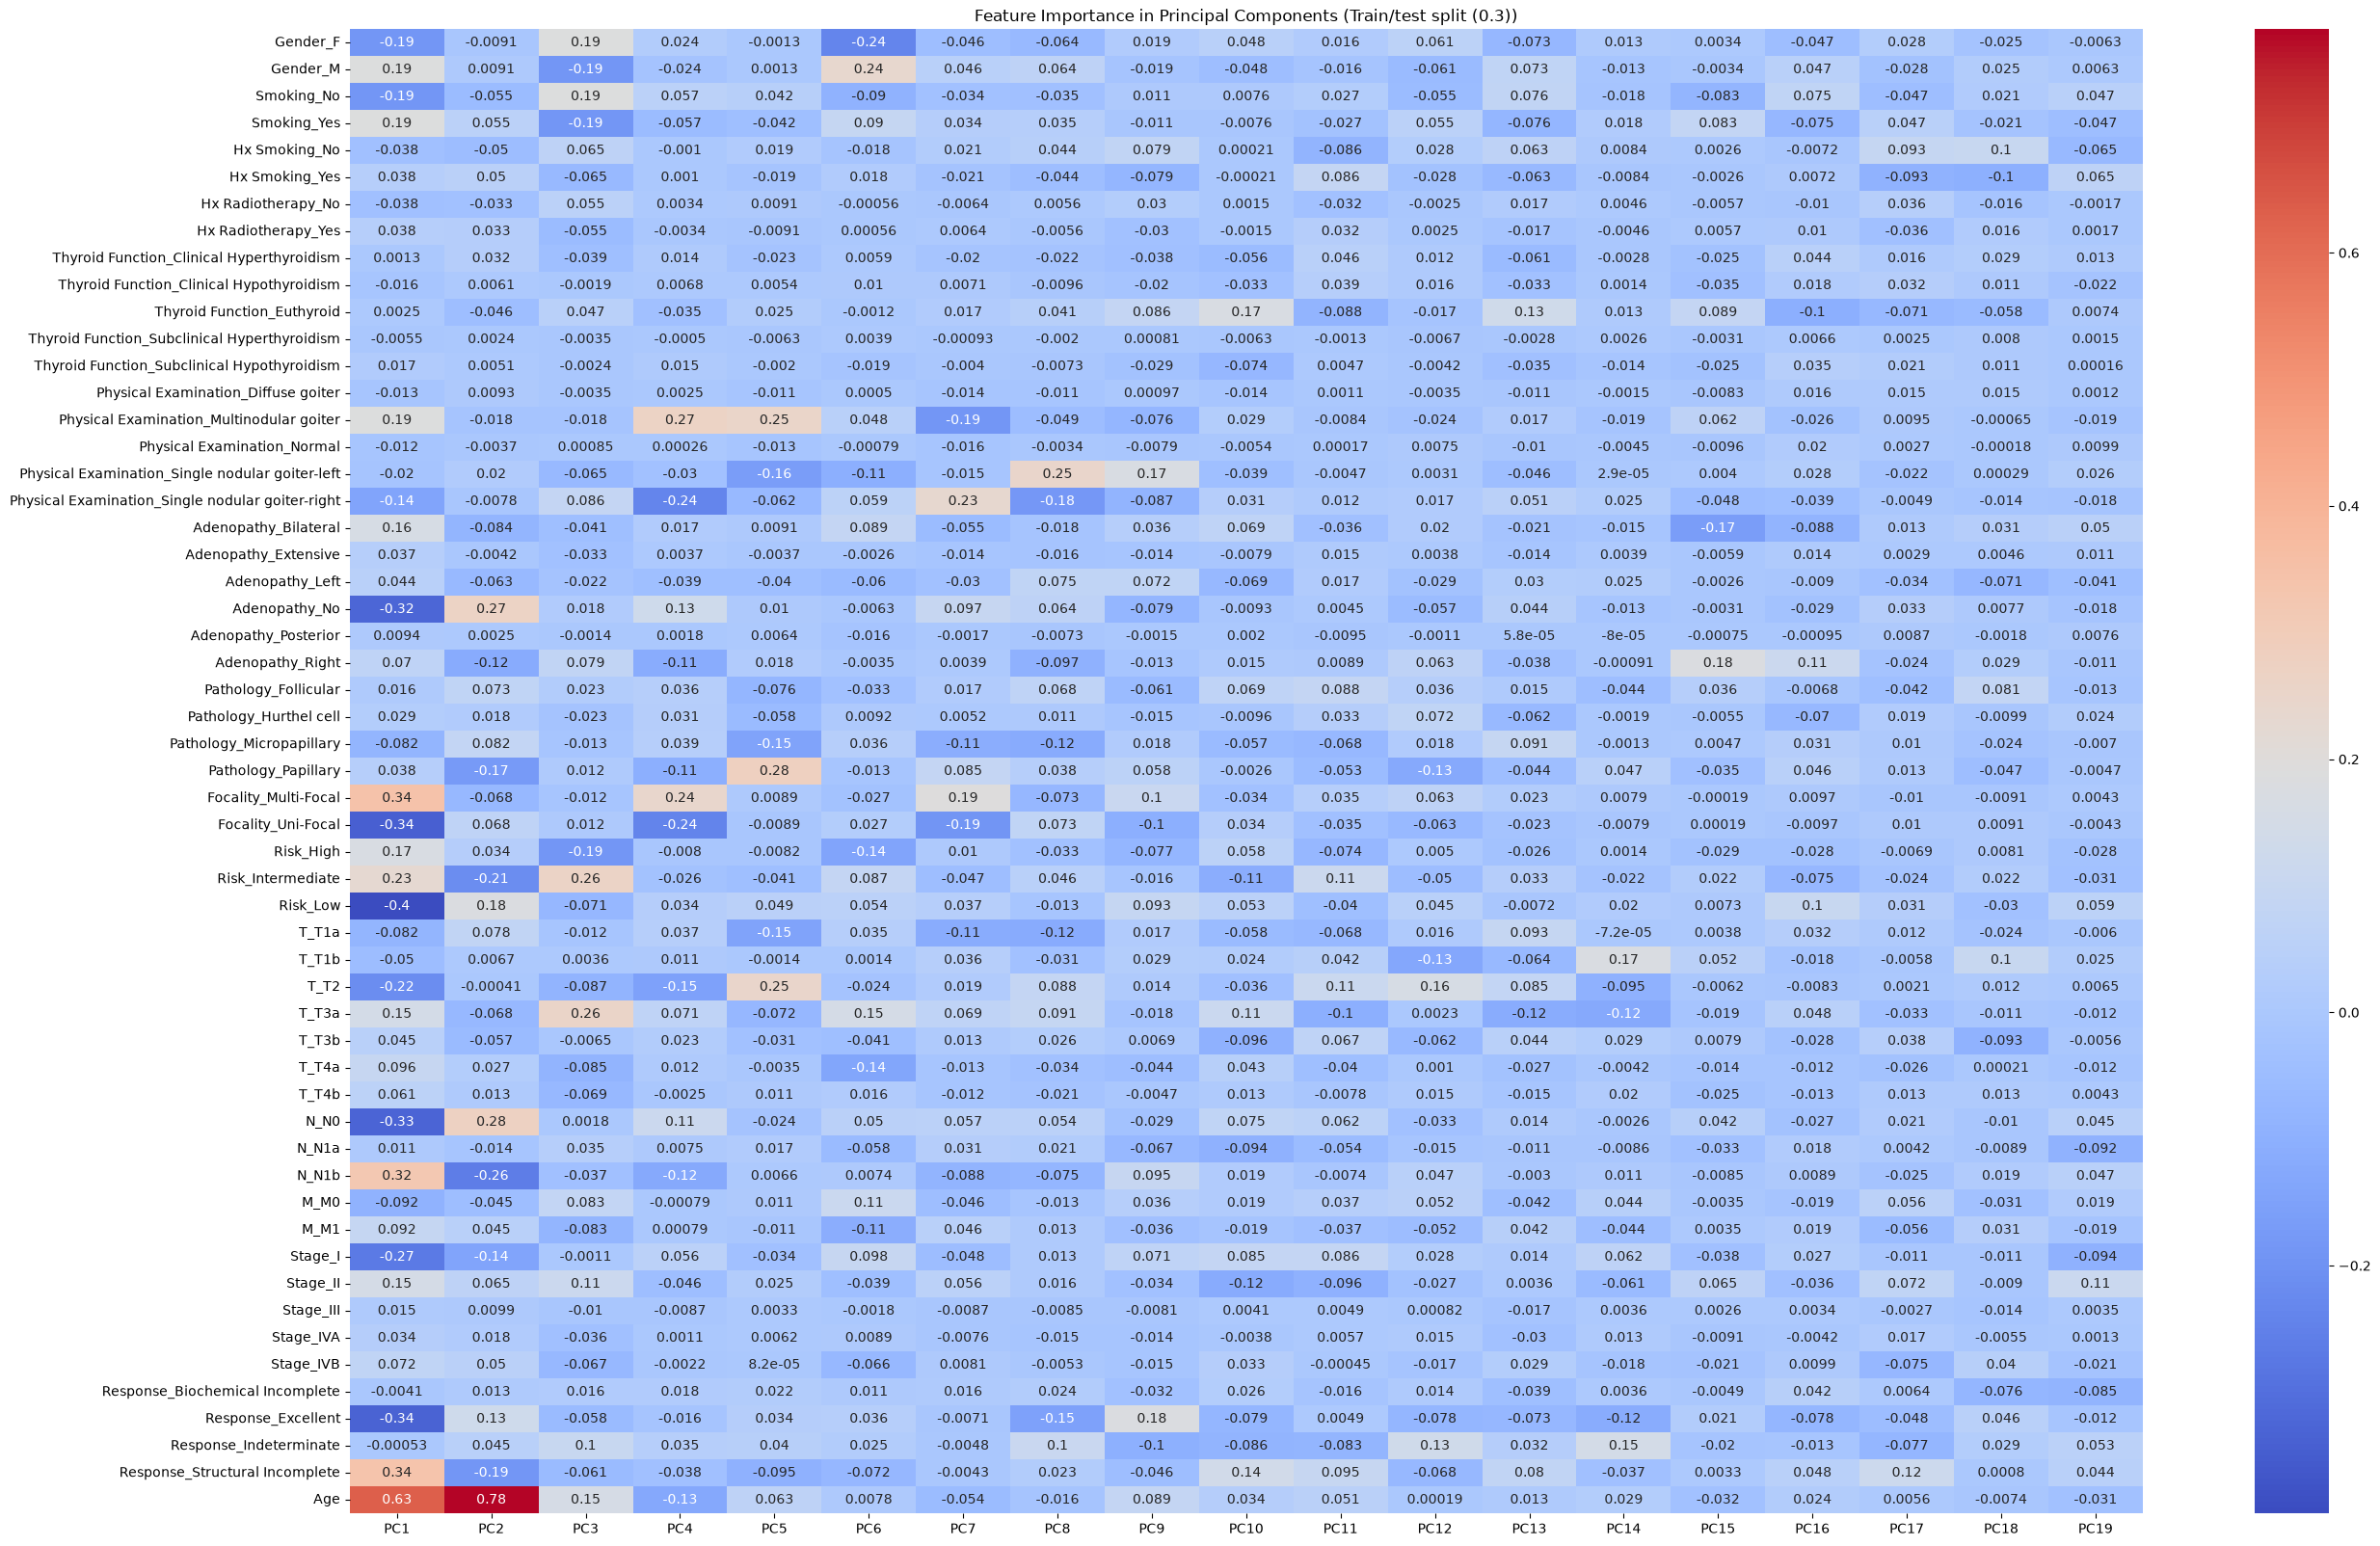

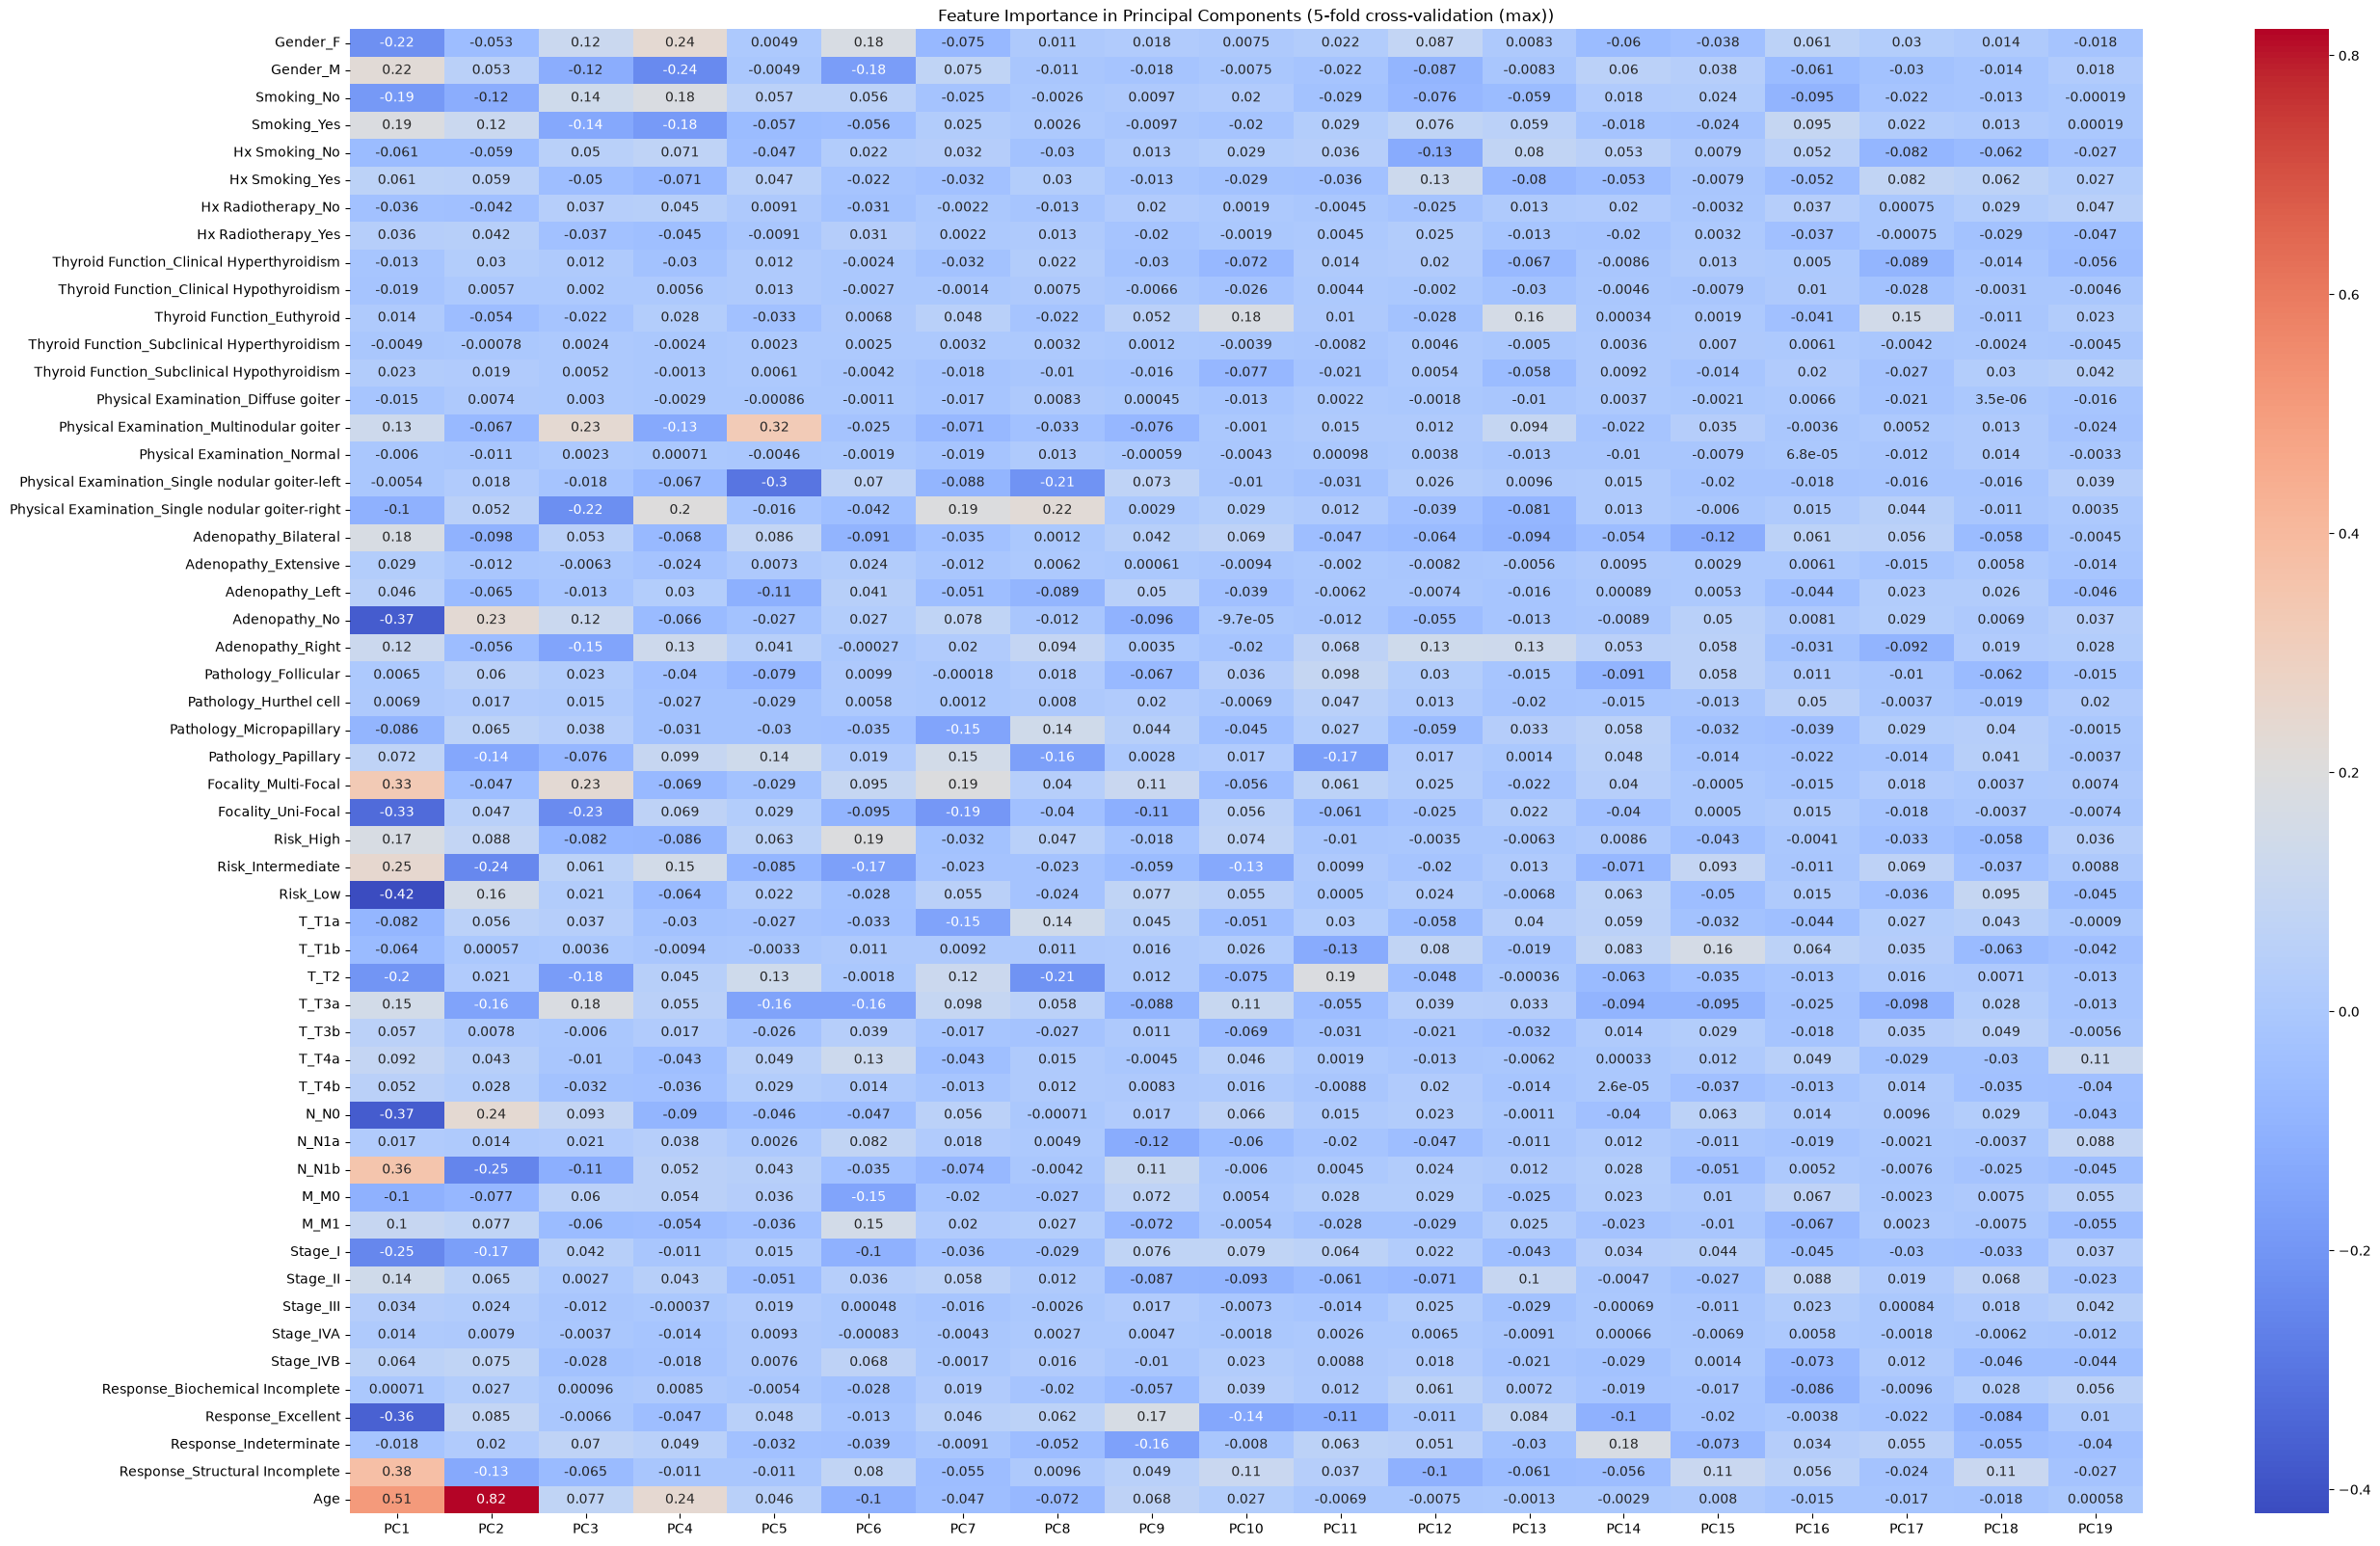

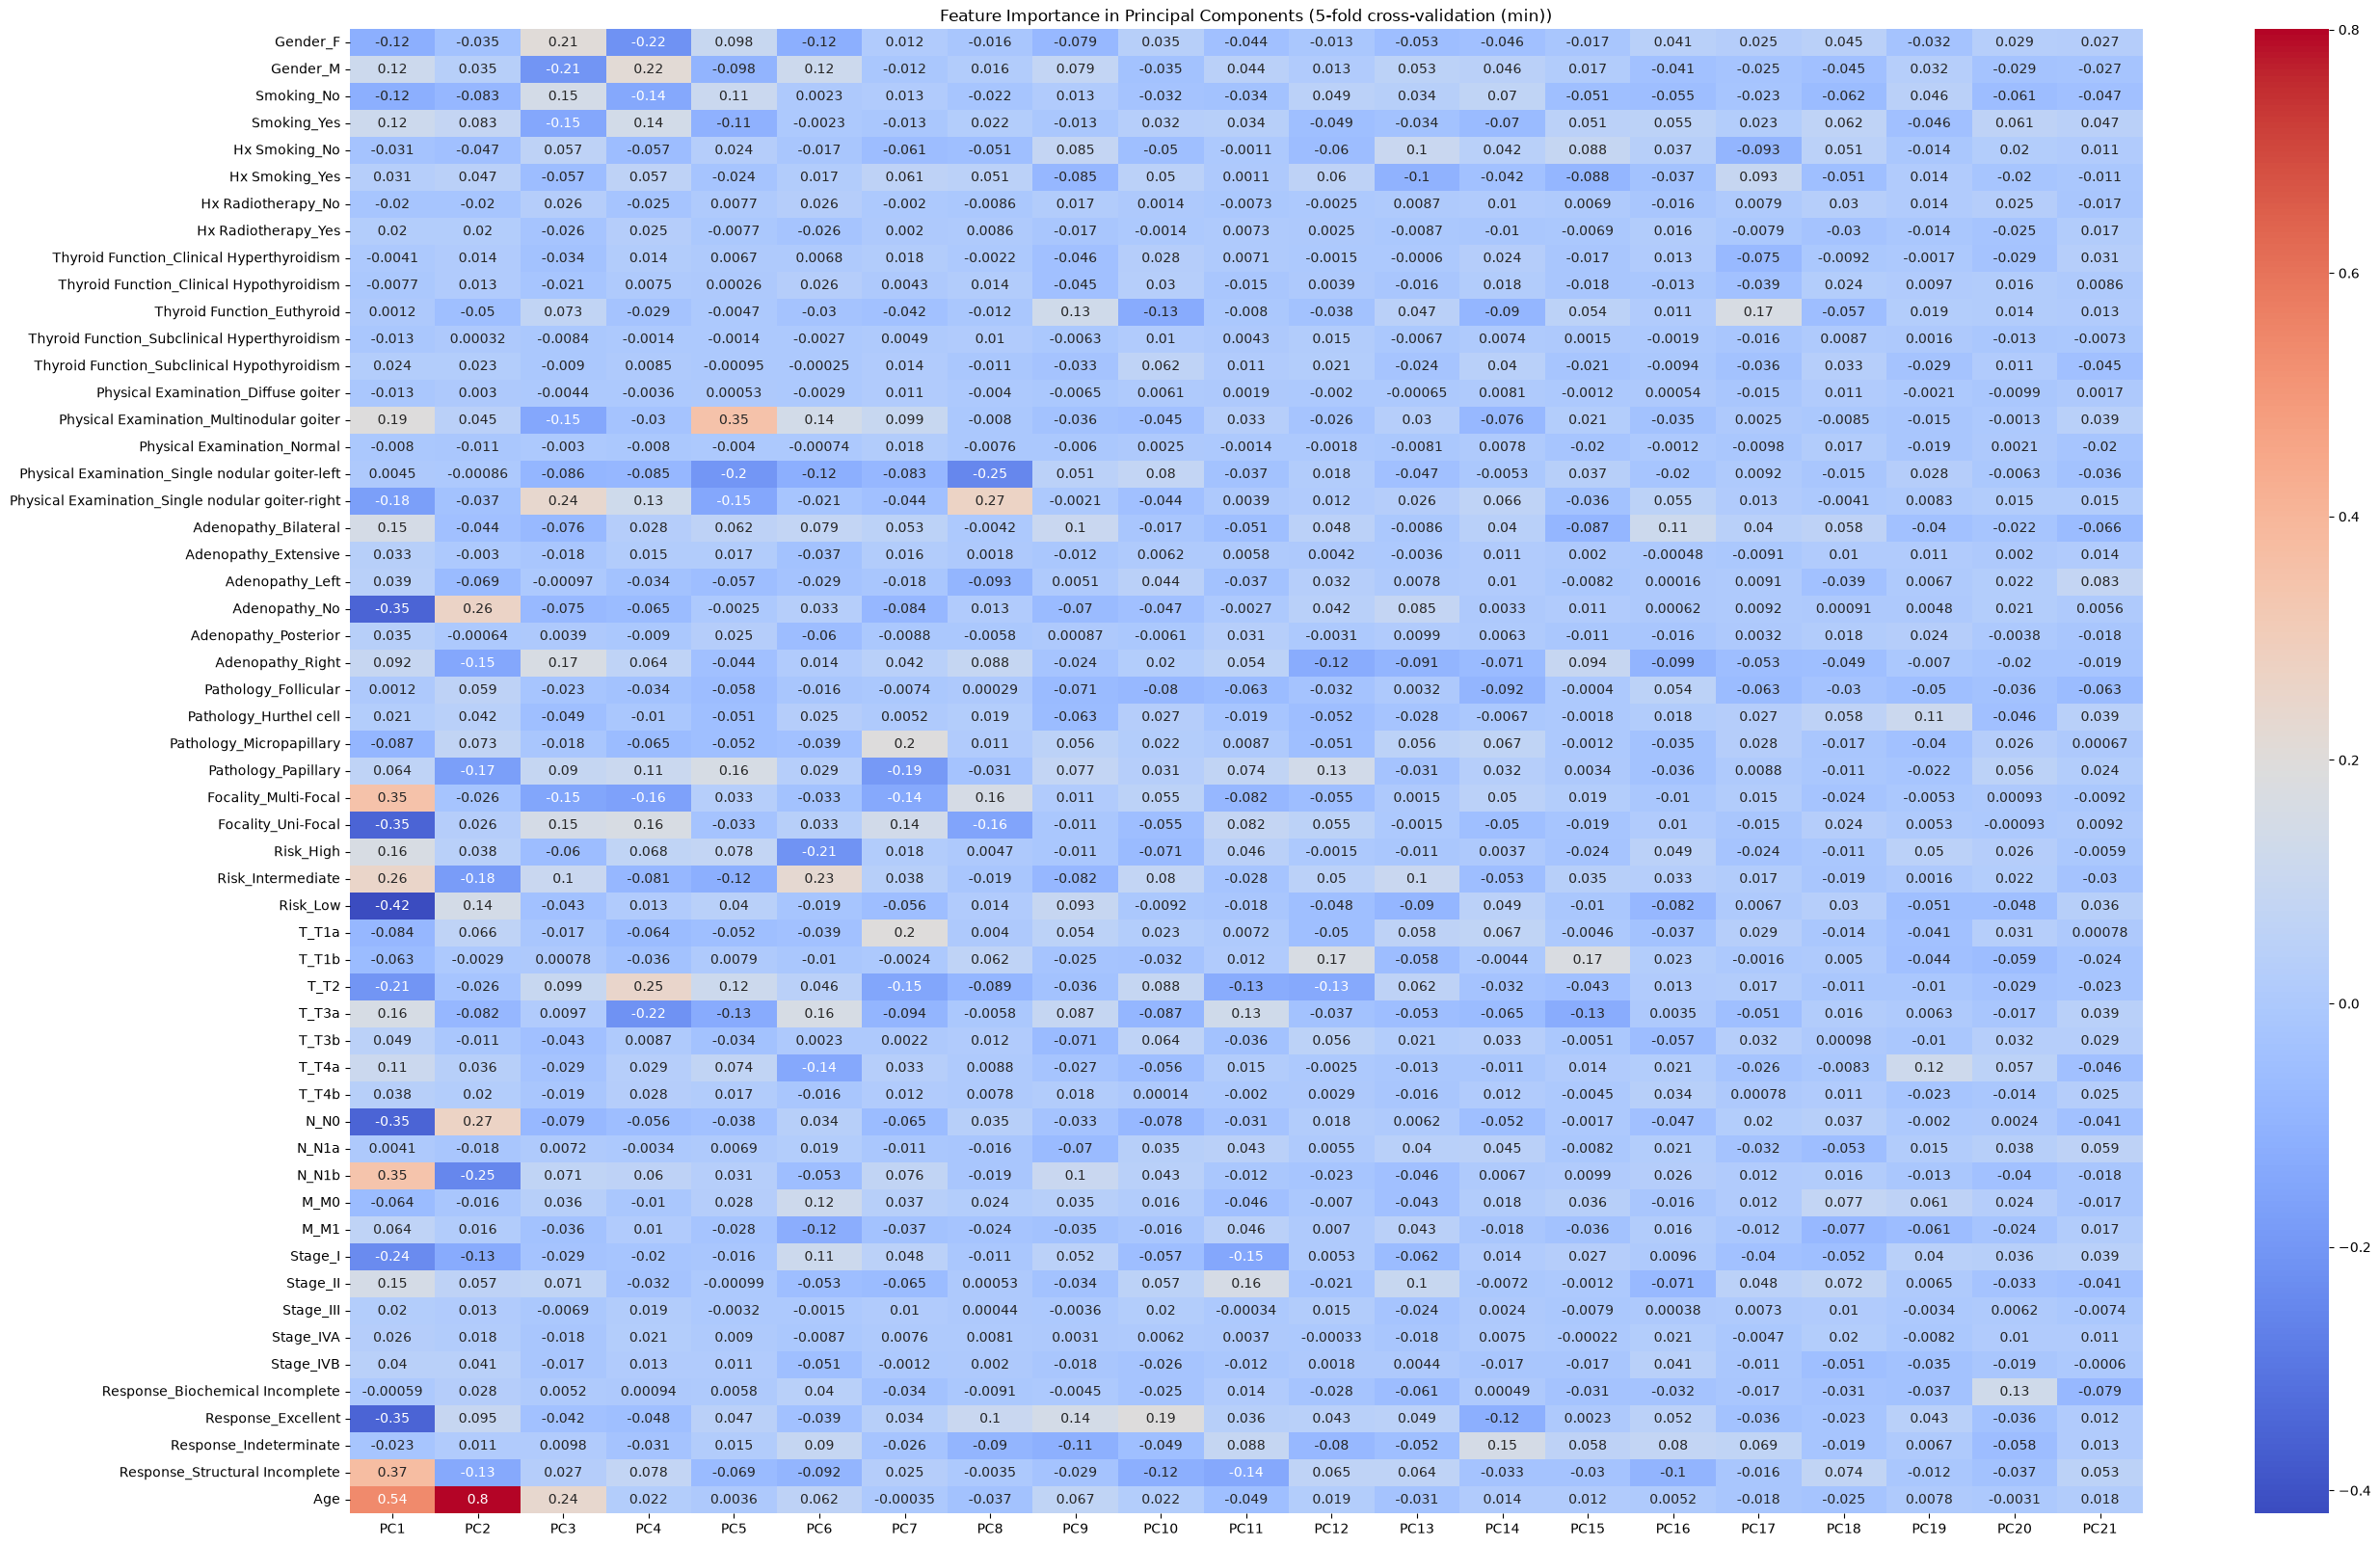

In [24]:
for result in results:
    plt.figure(figsize=(30, 20))
    sns.heatmap(result["FeatLoad"], annot=True, cmap="coolwarm", 
                xticklabels=result["FeatLoad"].columns,
                yticklabels=result["FeatLoad"].index)
    plt.title(f"Feature Importance in Principal Components ({result["Method"]})")